# highconcmss figure style — worked reference

Every convention in `STYLE_GUIDE.md`, demonstrated on **synthetic data** so the whole
notebook runs anywhere with just numpy + matplotlib. Nothing here touches the real
dataset or the `pls_explorer` / `glom_explorer` packages.

**What this is for.** The guide states the target; this notebook shows one way to hit
it, in enough detail that you can port the conventions to whatever you actually plot
in. The matplotlib calls are readable as a specification even if you never run them —
if you work in MATLAB or R, read the *values* (sizes, widths, orders, limits) and the
comments, not the API.

**How to use it**

- §0 is the block to copy into your own script. Everything after it depends on §0.
- §1–§3 cover the cross-cutting rules: colour, type, axes.
- §4 is one section per figure type.
- §5 covers the concentration conditions — the paper's primary categorical
  scheme — and the panels built on them.
- §6 demonstrates the Illustrator-safe constructions — these are the ones that look
  like fussy detail and aren't.
- §7 exports, and verifies the export is actually Illustrator-ready.
- §8 assembles a multi-panel figure at final print size.

Outputs are written to `examples_output/`.

---
## §0 · Setup — the house style block

This is the part to copy. It does four things: pins the export settings that make
Illustrator behave, defines the palette, defines the save helper, and defines two
small axis helpers used everywhere below.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba

# ---------------------------------------------------------------------------
# Export settings — see STYLE_GUIDE §6. These four lines are the whole
# "Illustrator contract" on the matplotlib side.
# ---------------------------------------------------------------------------
mpl.rcParams["svg.fonttype"] = "none"    # SVG text stays <text>, i.e. editable
mpl.rcParams["pdf.fonttype"] = 42        # TrueType, not Type 3
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "sans-serif"
# Arial first: it exists on the Macs where figures get assembled, so Illustrator
# does not flag imported text as a missing font and silently substitute it.
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]

# House type scale (points), STYLE_GUIDE §3
FS_TICK, FS_LABEL, FS_TITLE, FS_PANEL = 8, 9, 10, 11

mpl.rcParams["font.size"] = FS_LABEL
mpl.rcParams["axes.labelsize"] = FS_LABEL
mpl.rcParams["axes.titlesize"] = FS_TITLE
mpl.rcParams["xtick.labelsize"] = FS_TICK
mpl.rcParams["ytick.labelsize"] = FS_TICK
mpl.rcParams["legend.fontsize"] = FS_TICK
mpl.rcParams["axes.grid"] = False

# ---------------------------------------------------------------------------
# Palette — STYLE_GUIDE §2. Reference values live in style/palette/*.csv;
# these are the same numbers.
# ---------------------------------------------------------------------------
SEQ = plt.cm.magma                                  # sequential: activation, magnitudes
DIV = LinearSegmentedColormap.from_list(            # diverging: signed weights
    "teal_gainsboro_orrd",
    ["#01665e", "#5ab4ac", "gainsboro", "#fc8d59", "#b30000"])

CLUSTER_LABELS = list("ABCDEFG")
CLUSTER_COLORS = plt.cm.tab10(np.arange(7))         # fixed A-G across the whole paper

GAINSBORO = "#dcdcdc"      # below floor / not measured / no data
IDENTITY  = "0.45"         # identity + unity lines (== #737373)
BOUNDARY  = "black"        # cluster/block boundaries
BOUNDARY_LW = 0.8

C_PRIMARY   = "#0072b2"    # Okabe-Ito blue      - primary metric (Q2)
C_OVERFIT   = "#d55e00"    # Okabe-Ito vermilion - overfit / canonical comparison
C_WIN       = "#009e73"    # Okabe-Ito green     - "wins"
C_LOSE      = "#888888"    #                     - "loses" / neutral
C_SHUFFLED  = "#bbbbbb"    # nulls and shuffles are ALWAYS grey
C_NMF       = "#9b5bd0"
C_PCA       = "#777777"

OUT = Path("examples_output")
OUT.mkdir(exist_ok=True)


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def despine(ax, keep=("left", "bottom")):
    """Top and right spines off on every data panel (STYLE_GUIDE §4)."""
    for s in ("top", "right", "left", "bottom"):
        ax.spines[s].set_visible(s in keep)


def panel_label(ax, letter, x=-0.10, y=1.05):
    """Bold capital, outside the axes, upper-left. 'A', not '(a)'."""
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=FS_PANEL,
            fontweight="bold", va="bottom", ha="right")


def save(fig, stem, dpi=300):
    """The export trio (STYLE_GUIDE §6): white PNG to look at, transparent
    PDF + SVG with live text to assemble in Illustrator."""
    for ext in ("png", "pdf", "svg"):
        fig.savefig(OUT / f"{stem}.{ext}", dpi=dpi, bbox_inches="tight",
                    facecolor="white" if ext == "png" else "none",
                    transparent=(ext != "png"))
    print(f"saved {stem}.png / .pdf / .svg")


# Confirm which font actually resolved. If this prints DejaVu Sans, Arial is not
# installed here and your exported text will not match the rest of the figure set.
_resolved = mpl.font_manager.FontProperties(
    family=mpl.rcParams["font.sans-serif"]).get_name()
print(f"style block loaded · resolved sans-serif font: {_resolved}")

style block loaded · resolved sans-serif font: Arial


### Synthetic data

A fake experiment with the same *shape* as the real one: 200 glomeruli in 7 spatial
clusters, 40 odorants, a low- and a high-concentration response, and a "model
prediction" that is deliberately shrunken toward the mean — which is exactly the
property the real figures have to show honestly.

In [2]:
rng = np.random.default_rng(11)

N_GLOM, N_ODOR, K = 200, 40, 7

# glomerulus positions: 7 spatial blobs on a dorsal-surface-ish frame
centres = np.array([[.25,.75],[.5,.85],[.75,.72],[.2,.4],[.5,.5],[.8,.38],[.5,.18]])
glom_cluster = rng.integers(0, K, N_GLOM)
xy = centres[glom_cluster] + rng.normal(0, .062, (N_GLOM, 2))

# cluster x odorant "rule" matrix, then per-glomerulus responses from it
rule = rng.gamma(1.6, .8, (K, N_ODOR))
rule[rng.random((K, N_ODOR)) < .35] = 0                 # sparse: most pairs silent
high = rule[glom_cluster] * rng.lognormal(0, .35, (N_GLOM, N_ODOR))
low  = high * rng.uniform(.15, .45, (N_GLOM, N_ODOR))   # low conc: scaled-down high

# a "prediction": shrunken toward the mean, with noise that grows with signal —
# so per-pair accuracy looks poor while cluster-level structure is recovered well.
# That gap is the real result these figures have to show honestly.
pred = .72 * high + .28 * high.mean() + rng.normal(0, 1.0, high.shape) * np.sqrt(high + .35)
pred = np.clip(pred, 0, None)

# odorants belong to chemical families
chem_class = rng.integers(0, 5, N_ODOR)
CHEM_NAMES = ["acids", "aldehydes", "esters", "ketones", "alcohols"]

print(f"low {low.shape} · high {high.shape} · {K} clusters · "
      f"{(high == 0).mean():.0%} of glom x odorant pairs silent")

low (200, 40) · high (200, 40) · 7 clusters · 34% of glom x odorant pairs silent


---
## §1 · Colour

Three families, and the rule for choosing between them is about the *data*, not the
look: does the quantity run from nothing to a lot (sequential), does it have a
meaningful zero with two directions (diverging), or is it an unordered label
(categorical)?

saved 01_colour.png / .pdf / .svg


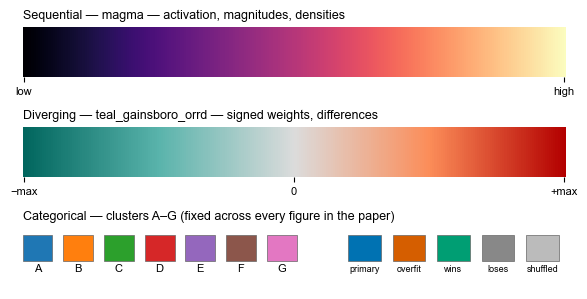

In [3]:
fig = plt.figure(figsize=(7.0, 3.4))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 1.25], hspace=.95)

grad = np.linspace(0, 1, 256).reshape(1, -1)

# --- sequential -----------------------------------------------------------
ax = fig.add_subplot(gs[0])
ax.imshow(grad, aspect="auto", cmap=SEQ, interpolation="nearest")
ax.set_title("Sequential — magma — activation, magnitudes, densities",
             fontsize=FS_LABEL, loc="left")
ax.set_yticks([]); ax.set_xticks([0, 255]); ax.set_xticklabels(["low", "high"])
despine(ax, keep=())

# --- diverging ------------------------------------------------------------
ax = fig.add_subplot(gs[1])
ax.imshow(grad, aspect="auto", cmap=DIV, interpolation="nearest")
ax.set_title("Diverging — teal_gainsboro_orrd — signed weights, differences",
             fontsize=FS_LABEL, loc="left")
ax.set_yticks([]); ax.set_xticks([0, 127.5, 255])
ax.set_xticklabels(["\N{MINUS SIGN}max", "0", "+max"])
despine(ax, keep=())

# --- categorical ----------------------------------------------------------
ax = fig.add_subplot(gs[2]); ax.set_axis_off()
ax.set_title("Categorical — clusters A–G (fixed across every figure in the paper)",
             fontsize=FS_LABEL, loc="left")
for i, lab in enumerate(CLUSTER_LABELS):
    ax.add_patch(plt.Rectangle((i * .075, .45), .055, .42, facecolor=CLUSTER_COLORS[i],
                               edgecolor="0.4", lw=.5, transform=ax.transAxes))
    ax.text(i * .075 + .027, .28, lab, ha="center", fontsize=FS_TICK,
            transform=ax.transAxes)
for j, (c, lab) in enumerate([(C_PRIMARY, "primary"), (C_OVERFIT, "overfit"),
                              (C_WIN, "wins"), (C_LOSE, "loses"),
                              (C_SHUFFLED, "shuffled")]):
    ax.add_patch(plt.Rectangle((.60 + j * .082, .45), .06, .42, facecolor=c,
                               edgecolor="0.4", lw=.5, transform=ax.transAxes))
    ax.text(.60 + j * .082 + .03, .28, lab, ha="center", fontsize=6.5,
            transform=ax.transAxes)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

save(fig, "01_colour"); plt.show()

**The one rule that gets broken most often:** a diverging map has to be *centred on
zero*. `vmin=-vmax`, or a norm that pins the centre. Below, the same weight matrix
with the centre pinned and with it left to the data range — the second one invents a
sign flip that isn't in the data.

saved 01b_diverging_centre.png / .pdf / .svg


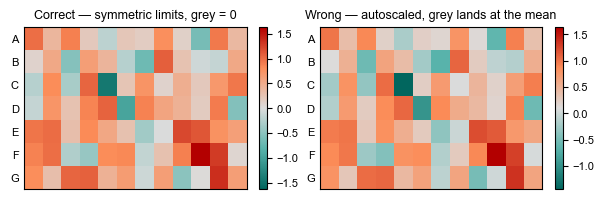

In [4]:
W = rng.normal(.35, .55, (K, 12))          # note: mean is positive, not zero

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.1))

vmax = np.abs(W).max()
im = axes[0].imshow(W, cmap=DIV, vmin=-vmax, vmax=vmax, interpolation="nearest",
                    aspect="auto")
axes[0].set_title("Correct — symmetric limits, grey = 0", fontsize=FS_LABEL)
fig.colorbar(im, ax=axes[0], fraction=.046)

im = axes[1].imshow(W, cmap=DIV, interpolation="nearest", aspect="auto")  # autoscaled
axes[1].set_title("Wrong — autoscaled, grey lands at the mean", fontsize=FS_LABEL)
fig.colorbar(im, ax=axes[1], fraction=.046)

for ax in axes:
    ax.set_yticks(range(K)); ax.set_yticklabels(CLUSTER_LABELS)
    ax.set_xticks([]); ax.tick_params(length=0)

save(fig, "01b_diverging_centre"); plt.show()

---
## §2 · Typography

Sizes are **final, on-the-page** sizes: ticks 8 pt, axis labels 9–10 pt, panel letters
11–12 pt bold. The panel below is drawn at the size it would print at, so what you see
is what a reader sees.

saved 02_typography.png / .pdf / .svg


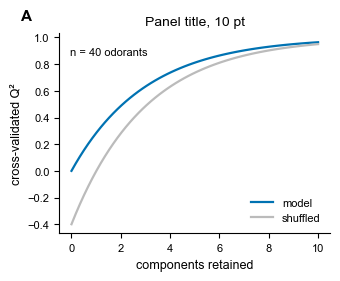

In [5]:
fig, ax = plt.subplots(figsize=(3.5, 2.6))     # single-column width

x = np.linspace(0, 10, 60)
ax.plot(x, 1 - np.exp(-x / 3), lw=1.6, color=C_PRIMARY, label="model")
ax.plot(x, 1 - np.exp(-x / 3) * 1.4, lw=1.6, color=C_SHUFFLED, label="shuffled")

ax.set_xlabel("components retained")          # 9 pt via rcParams
ax.set_ylabel("cross-validated Q²")
ax.set_title("Panel title, 10 pt")
ax.legend(frameon=False, loc="lower right")
ax.text(.04, .93, "n = 40 odorants", transform=ax.transAxes, fontsize=FS_TICK,
        va="top")                              # stats in-panel, not in the title
panel_label(ax, "A")
despine(ax)

save(fig, "02_typography"); plt.show()

---
## §3 · Axes and geometry

Default matplotlib versus the house treatment. The differences are small individually
and obvious in aggregate: box → two spines, chunky ticks → 8 pt labels, grid off,
panel letter placed outside the axes.

saved 03_axes.png / .pdf / .svg


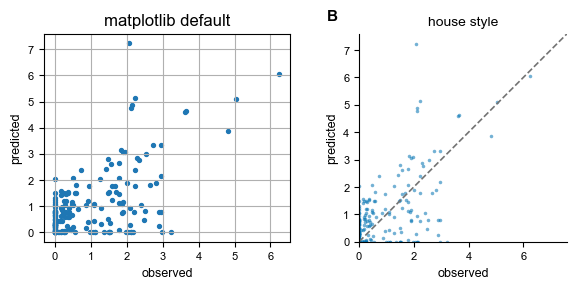

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
d = pred[:, 3]; o = high[:, 3]

with mpl.rc_context(mpl.rcParamsDefault):      # a deliberately untouched panel
    axes[0].scatter(o, d, s=8)
    axes[0].set_xlabel("observed"); axes[0].set_ylabel("predicted")
    axes[0].set_title("matplotlib default")
    axes[0].grid(True)

ax = axes[1]
ax.scatter(o, d, s=6.5, linewidths=0, alpha=.55, color=C_PRIMARY)  # house panel
lim = max(o.max(), d.max()) * 1.05
ax.plot([0, lim], [0, lim], ls="--", lw=1.2, color=IDENTITY, zorder=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("observed"); ax.set_ylabel("predicted")
ax.set_title("house style")
despine(ax)
panel_label(ax, "B")

save(fig, "03_axes"); plt.show()

**One exception, worth stating because it looks like an inconsistency.** "Top and right
spines off" applies to panels with *data axes* — scatters, lines, bars. A matrix or an
image keeps its full frame: the frame is the extent of the data, not decoration, and
removing it leaves the cells floating. Every heatmap below is drawn with its box intact.

---
## §4 · By figure type

### §4.1 · Scatter and parity

Two marker regimes, and mixing them up is what makes a parity plot unreadable:

- **dense cloud** — small (area 1–7 pt²), no edge, alpha 0.2–0.6, so overplotting reads as density
- **emphasis** — large (area 40–150 pt²), white edge ~1 pt, on top; the white ring is what lifts a point off the cloud

Parity panels are square with equal limits, and the identity line goes *under* the data.

saved 04_1_parity.png / .pdf / .svg


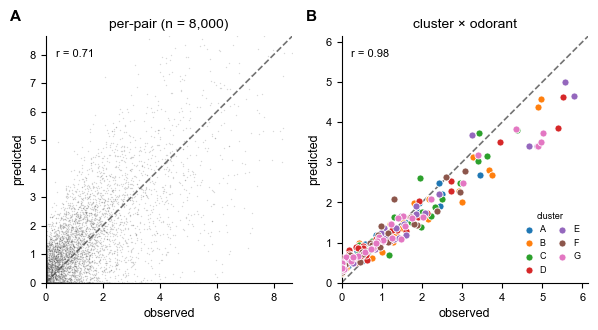

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.3))

# --- per-pair parity: the honest, unflattering view ------------------------
ax = axes[0]
o, p = high.ravel(), pred.ravel()
ax.scatter(o, p, s=1, linewidths=0, alpha=.20, color="0.25", zorder=2)
lim = np.percentile(o, 99.8)
ax.plot([0, lim], [0, lim], ls="--", lw=1.2, color=IDENTITY, zorder=1)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="observed", ylabel="predicted",
       title="per-pair (n = 8,000)")
ax.set_aspect("equal")
r = np.corrcoef(o, p)[0, 1]
ax.text(.04, .95, f"r = {r:.2f}", transform=ax.transAxes, fontsize=FS_TICK, va="top")
despine(ax); panel_label(ax, "A")

# --- cluster x odorant parity: where the model is actually good ------------
ax = axes[1]
obs_c = np.column_stack([high[glom_cluster == k].mean(0) for k in range(K)])
prd_c = np.column_stack([pred[glom_cluster == k].mean(0) for k in range(K)])
for k in range(K):
    ax.scatter(obs_c[:, k], prd_c[:, k], s=26, color=CLUSTER_COLORS[k],
               edgecolors="white", linewidths=.6, zorder=3, label=CLUSTER_LABELS[k])
lim = max(obs_c.max(), prd_c.max()) * 1.06
ax.plot([0, lim], [0, lim], ls="--", lw=1.2, color=IDENTITY, zorder=1)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="observed", ylabel="predicted",
       title="cluster × odorant")
ax.set_aspect("equal")
r = np.corrcoef(obs_c.ravel(), prd_c.ravel())[0, 1]
ax.text(.04, .95, f"r = {r:.2f}", transform=ax.transAxes, fontsize=FS_TICK, va="top")
ax.legend(frameon=False, fontsize=6.5, loc="lower right", ncol=2,
          handletextpad=.2, columnspacing=.8, title="cluster", title_fontsize=6.5)
despine(ax); panel_label(ax, "B")

save(fig, "04_1_parity"); plt.show()

### §4.2 · Heatmaps and matrices

Four things carry information here and all four are easy to get wrong:
**nearest-neighbour** (never smooth discrete measurements), **row/column order**
(state it in the caption), **boundaries** (black, 0.8 pt), and **missing cells**
(opaque gainsboro, never transparent — see §5).

saved 04_2_heatmap.png / .pdf / .svg


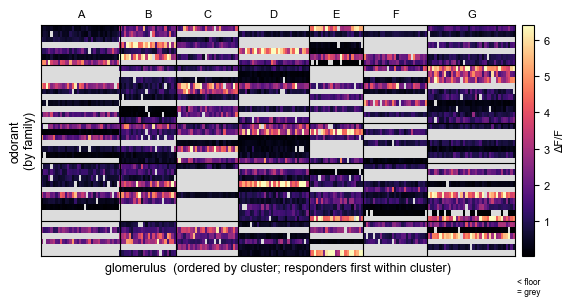

In [8]:
# order glomeruli by cluster; within a cluster, responders before non-responders
responder = (high > .35).mean(1) > .25
order = np.lexsort((~responder, glom_cluster))
M = high[order][:, np.argsort(chem_class)]

# knock out a few measurements so "missing" has something to show
M = M.astype(float); M[rng.random(M.shape) < .02] = np.nan

cmap = SEQ.copy()
cmap.set_bad(GAINSBORO)        # NaN  -> opaque grey
cmap.set_under(GAINSBORO)      # sub-floor -> the same grey

fig, ax = plt.subplots(figsize=(6.4, 3.0))
im = ax.imshow(M.T, aspect="auto", cmap=cmap, vmin=.05, vmax=np.nanpercentile(M, 99),
               interpolation="nearest")          # NEAREST, always

# cluster boundaries over the cells
bounds = np.where(np.diff(glom_cluster[order]) != 0)[0] + .5
for b in bounds:
    ax.axvline(b, color=BOUNDARY, lw=BOUNDARY_LW)
mids = np.concatenate([[0], bounds, [len(order)]])
for k in range(K):
    ax.text((mids[k] + mids[k + 1]) / 2, -1.5, CLUSTER_LABELS[k], ha="center",
            va="bottom", fontsize=FS_TICK)

# chemical-family boundaries on the odorant axis
cbounds = np.where(np.diff(np.sort(chem_class)) != 0)[0] + .5
for b in cbounds:
    ax.axhline(b, color=BOUNDARY, lw=BOUNDARY_LW)

ax.set_xlabel("glomerulus  (ordered by cluster; responders first within cluster)")
ax.set_ylabel("odorant\n(by family)")
ax.set_xticks([]); ax.set_yticks([])
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=.03, pad=.015)
cb.set_label("ΔF/F", fontsize=FS_TICK); cb.ax.tick_params(labelsize=FS_TICK)
cb.ax.text(.5, -.09, "< floor\n= grey", transform=cb.ax.transAxes, ha="center",
           va="top", fontsize=6)

save(fig, "04_2_heatmap"); plt.show()

### §4.3 · Spatial maps — glomerular topography

The rule that matters more than any styling choice: **maps that will be compared share
one colour scale, and one colorbar.** Left pair below is correct. The right-hand panel
re-plots the same prediction on its own autoscaled limits — it looks like a better
prediction, and that impression is an artefact of the scale.

saved 04_3_topography.png / .pdf / .svg


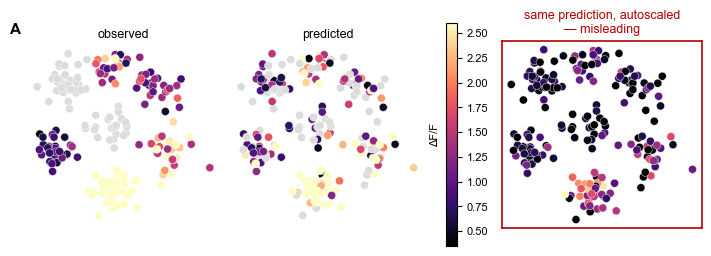

In [9]:
MAP_VMIN, MAP_VMAX, MAP_PT = .35, 2.6, 34
odor = 7

def topo(ax, values, title, vmin=MAP_VMIN, vmax=MAP_VMAX):
    cmap = SEQ.copy(); cmap.set_under(GAINSBORO)   # below floor recedes to context
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=values, s=MAP_PT, cmap=cmap,
                    vmin=vmin, vmax=vmax, linewidths=.3, edgecolors="white")
    ax.set_title(title, fontsize=FS_LABEL)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    despine(ax, keep=())
    return sc

fig = plt.figure(figsize=(7.0, 2.8), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.05], wspace=.06)

ax0 = fig.add_subplot(gs[0]); sc = topo(ax0, high[:, odor], "observed")
ax1 = fig.add_subplot(gs[1]); topo(ax1, pred[:, odor], "predicted")
panel_label(ax0, "A", x=-.04)

# ONE shared colorbar for the pair. Label on the LEFT of the bar, so it can never
# collide with whatever sits in the next column — the repo does the same.
cb = fig.colorbar(sc, ax=[ax0, ax1], fraction=.05, pad=.02, shrink=.82)
cb.ax.yaxis.set_label_position("left")
cb.set_label("ΔF/F", fontsize=FS_TICK, labelpad=4)
cb.ax.tick_params(labelsize=FS_TICK)

ax3 = fig.add_subplot(gs[2])
topo(ax3, pred[:, odor], "", vmin=pred[:, odor].min(), vmax=pred[:, odor].max())
for sp in ax3.spines.values():
    sp.set_visible(True); sp.set_color("#b30000"); sp.set_linewidth(1.2)
ax3.set_title("same prediction, autoscaled\n\N{EM DASH} misleading", fontsize=FS_LABEL,
              color="#b30000")

save(fig, "04_3_topography"); plt.show()

### §4.4 · Line plots and sweeps

Real series in colour, nulls in grey, spread as a filled band with no edge, and the
**chosen operating point marked explicitly** rather than left for the reader to infer.

saved 04_4_sweep.png / .pdf / .svg


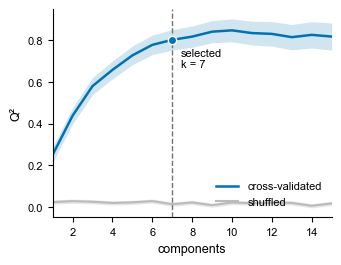

In [10]:
ranks = np.arange(1, 16)
q2 = 1 - np.exp(-ranks / 3.2) - ranks * .012 + rng.normal(0, .006, ranks.size)
spread = .035 + .002 * ranks
null = q2 * 0 + rng.normal(.02, .006, ranks.size)
CHOSEN = 7

fig, ax = plt.subplots(figsize=(3.6, 2.7))
ax.fill_between(ranks, q2 - spread, q2 + spread, color=C_PRIMARY, alpha=.18,
                linewidth=0)                      # band: no edge
ax.plot(ranks, q2, lw=1.8, color=C_PRIMARY, label="cross-validated")
ax.fill_between(ranks, null - .01, null + .01, color=C_SHUFFLED, alpha=.35, linewidth=0)
ax.plot(ranks, null, lw=1.5, color=C_SHUFFLED, label="shuffled")

ax.axvline(CHOSEN, color=IDENTITY, ls="--", lw=1.0, zorder=1)
ax.plot([CHOSEN], [q2[CHOSEN - 1]], "o", ms=6, color=C_PRIMARY,
        markeredgecolor="white", markeredgewidth=1.0, zorder=4)
ax.annotate(f"selected\nk = {CHOSEN}", (CHOSEN, q2[CHOSEN - 1]),
            xytext=(6, -20), textcoords="offset points", fontsize=FS_TICK)

ax.set(xlabel="components", ylabel="Q²", xlim=(1, 15))
ax.legend(frameon=False, loc="lower right")
despine(ax)

save(fig, "04_4_sweep"); plt.show()

### §4.5 · Bar charts

Used sparingly, deliberately. With few observations a bar hides the thing a reader
most wants — the spread — so show the points over it, or skip the bar entirely.

saved 04_5_bar.png / .pdf / .svg


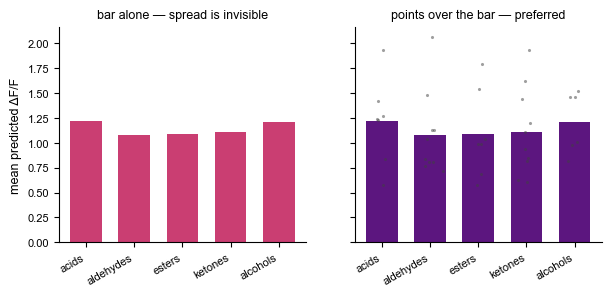

In [11]:
groups = CHEM_NAMES
vals = [pred[:, chem_class == c].mean(0) for c in range(5)]

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=True)

ax = axes[0]
ax.bar(range(5), [v.mean() for v in vals], color=SEQ(.55), width=.66,
       edgecolor="none", zorder=2)
ax.set_title("bar alone — spread is invisible", fontsize=FS_LABEL)

ax = axes[1]
ax.bar(range(5), [v.mean() for v in vals], color=SEQ(.28), width=.66,
       edgecolor="none", zorder=1)
for i, v in enumerate(vals):                       # individual observations on top
    jit = rng.normal(0, .07, v.size)
    ax.scatter(i + jit, v, s=5, color="0.25", alpha=.5, linewidths=0, zorder=3)
ax.set_title("points over the bar — preferred", fontsize=FS_LABEL)

for ax in axes:
    ax.set_xticks(range(5)); ax.set_xticklabels(groups, rotation=30, ha="right")
    ax.set_ylim(0)                                  # zero baseline, always
    despine(ax)
axes[0].set_ylabel("mean predicted ΔF/F")

save(fig, "04_5_bar"); plt.show()

### §4.6 · Schematics

Same fonts and palette as the data panels, so a schematic doesn't look imported from a
different paper. Build the pieces as separable objects — the whole point of a schematic
is that it gets re-labelled during revision.

saved 04_6_schematic.png / .pdf / .svg


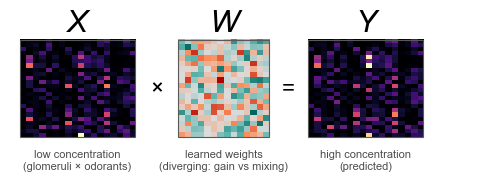

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 1.9))
ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, 3)

def block(x, w, data, cmap, label, vlim=None):
    ax.imshow(data, extent=(x, x + w, .55, 2.55), cmap=cmap, aspect="auto",
              interpolation="nearest",
              **({} if vlim is None else dict(vmin=-vlim, vmax=vlim)))
    ax.add_patch(plt.Rectangle((x, .55), w, 2.0, fill=False, edgecolor="0.35", lw=.8))
    ax.text(x + w / 2, 2.72, label, ha="center", fontsize=22, style="italic")

block(0.2, 2.4, low[:24, :18], SEQ, "X")
ax.text(3.05, 1.55, "×", ha="center", va="center", fontsize=16)
block(3.5, 1.9, rng.normal(0, 1, (18, 14)), DIV, "W", vlim=2.6)
ax.text(5.8, 1.55, "=", ha="center", va="center", fontsize=16)
block(6.2, 2.4, high[:24, :18], SEQ, "Y")

for x, t in [(1.4, "low concentration\n(glomeruli × odorants)"),
             (4.45, "learned weights\n(diverging: gain vs mixing)"),
             (7.4, "high concentration\n(predicted)")]:
    ax.text(x, .30, t, ha="center", va="top", fontsize=FS_TICK, color="0.3")

save(fig, "04_6_schematic"); plt.show()

---
## §5 · The concentration conditions

The paper's **primary** categorical scheme — `'most-sensitive'`, `'low'` (1x),
`'high'` (25x) — and the one that appears in the most panels. Okabe-Ito amber /
blue / vermilion: colourblind-safe, and the blue and vermilion are the same
values already used for accent series, so the palette stays small.

Two rules carry the weight: a condition is the **same colour in every figure in
the paper**, and legends run **weakest → strongest**, matching the physical
order rather than alphabetical or whatever the dataframe happened to produce.

saved 05_conditions.png / .pdf / .svg


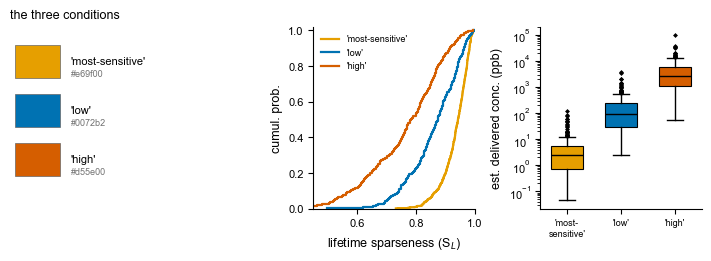

In [13]:
CONDITIONS = ("most-sensitive", "low", "high")
CONDITION_COLORS = {
    "most-sensitive": "#e69f00",   # Okabe-Ito amber
    "low":            "#0072b2",   # 1x   — same as C_PRIMARY
    "high":           "#d55e00",   # 25x  — same as C_OVERFIT
}

# Synthetic condition data with the qualitative shape of the real result:
# raising concentration broadens tuning, so lifetime sparseness falls.
cond_sparseness = {
    "most-sensitive": rng.beta(30, 2.0, 587),
    "low":            rng.beta(13, 2.0, 376),
    "high":           rng.beta(7,  2.2, 481),
}
# ...and delivered concentration climbs by orders of magnitude.
cond_delivered = {
    "most-sensitive": 10 ** rng.normal(0.3, 0.60, 200),
    "low":            10 ** rng.normal(2.0, 0.55, 200),
    "high":           10 ** rng.normal(3.4, 0.55, 200),
}

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.5),
                         gridspec_kw=dict(width_ratios=[1.25, .8, .8]),
                         layout="constrained")

# --- swatches -------------------------------------------------------------
ax = axes[0]; ax.set_axis_off()
ax.set_title("the three conditions", fontsize=FS_LABEL, loc="left")
for i, c in enumerate(CONDITIONS):
    ax.add_patch(plt.Rectangle((0.02, .72 - i * .27), .18, .18,
                               facecolor=CONDITION_COLORS[c], edgecolor="0.4",
                               lw=.5, transform=ax.transAxes))
    ax.text(.24, .81 - i * .27, f"'{c}'", fontsize=FS_TICK, va="center",
            transform=ax.transAxes)
    ax.text(.24, .74 - i * .27, CONDITION_COLORS[c], fontsize=6.5, va="center",
            color="0.45", transform=ax.transAxes)

# --- cumulative distributions (STYLE_GUIDE §5.6) --------------------------
ax = axes[1]
for c in CONDITIONS:                       # canonical order, not dict order
    v = np.sort(cond_sparseness[c])
    ax.step(v, np.arange(1, v.size + 1) / v.size, where="post", lw=1.6,
            color=CONDITION_COLORS[c], label=f"'{c}'")
ax.set(xlabel="lifetime sparseness (S$_L$)", ylabel="cumul. prob.",
       xlim=(.45, 1.0), ylim=(0, 1.02))
ax.legend(frameon=False, loc="upper left", fontsize=6.5)
despine(ax)

# --- box plots on a log axis (STYLE_GUIDE §5.7) ---------------------------
ax = axes[2]
bp = ax.boxplot([cond_delivered[c] for c in CONDITIONS], patch_artist=True,
                widths=.6, medianprops=dict(color="black", lw=1.0),
                flierprops=dict(marker="D", markersize=2.5,
                                markerfacecolor="black", markeredgecolor="none"))
for patch, c in zip(bp["boxes"], CONDITIONS):
    patch.set_facecolor(CONDITION_COLORS[c]); patch.set_edgecolor("black")
    patch.set_linewidth(.8)
ax.set_yscale("log")     # spans 4 orders of magnitude; linear is unreadable
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["'most-\nsensitive'", "'low'", "'high'"], fontsize=6.5)
ax.set_ylabel("est. delivered conc. (ppb)")
despine(ax)

save(fig, "05_conditions"); plt.show()

Note what the box plot does *not* do: force a zero baseline. That rule is about
bars. Delivered concentration spans four orders of magnitude and has no
meaningful zero, so a log axis is the honest choice — and the "zero baseline
always" instinct, applied here, would make the figure unreadable.

### §5.1 · Zero is not missing

This one bites specifically on sparse response matrices, which most of ours are.
A zero response is a **measurement**; grey means **not measured**. If you set a
floor above zero on a matrix that is 75% silent, three-quarters of the panel
turns grey and the figure claims the data are absent when they are merely zero.

saved 05_1_zero_vs_missing.png / .pdf / .svg


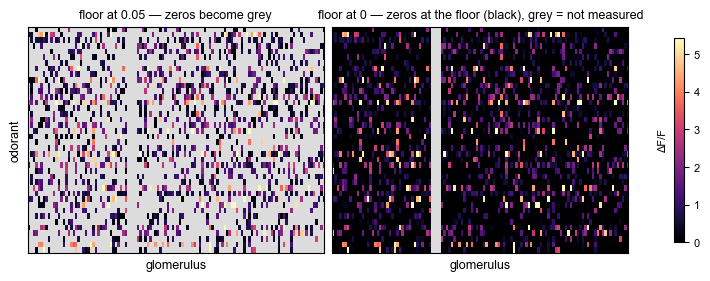

67% of cells are a measured zero; 3.3% are genuinely missing


In [14]:
# 75% silent, plus four genuinely unmeasured rows
S = high[:120, :].copy()
S[rng.random(S.shape) < .55] = 0.0
S[40:44, :] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7), layout="constrained")
for ax, vmin, title in [
        (axes[0], .05, "floor at 0.05 — zeros become grey"),
        (axes[1], 0.0, "floor at 0 — zeros at the floor (black), grey = not measured")]:
    cmap = SEQ.copy(); cmap.set_bad(GAINSBORO); cmap.set_under(GAINSBORO)
    im = ax.imshow(np.ma.masked_invalid(S).T, aspect="auto", cmap=cmap,
                   vmin=vmin, vmax=np.nanpercentile(S, 99),
                   interpolation="nearest")
    ax.set_title(title, fontsize=FS_LABEL)
    ax.set_xlabel("glomerulus"); ax.set_xticks([]); ax.set_yticks([])
    ax.tick_params(length=0)
axes[0].set_ylabel("odorant")
cb = fig.colorbar(im, ax=axes, fraction=.03, shrink=.9)
cb.ax.yaxis.set_label_position("left")
cb.set_label("ΔF/F", fontsize=FS_TICK); cb.ax.tick_params(labelsize=FS_TICK)

save(fig, "05_1_zero_vs_missing"); plt.show()
print(f"{(S == 0).mean():.0%} of cells are a measured zero; "
      f"{np.isnan(S).mean():.1%} are genuinely missing")

A floor above zero is still the right call sometimes — the example glomerular
maps in §4.3 use `vmin = 0.5` precisely so that weak responses recede and
shrunken predictions become visible. The rule is not "never set a floor", it is
**a floor hides data, so choose it deliberately and say so in the caption**.

### §5.2 · Rank-aligned response heatmaps

Sort each row by magnitude and centre it on its own peak. Tuning *breadth* then
reads directly, and rows stay comparable regardless of which odorant drove each
one. The x-axis is a **rank**, not an odorant identity — label it `+N | 1 | +N`
so nobody reads it as a shared ordering.

saved 05_2_rank_aligned.png / .pdf / .svg


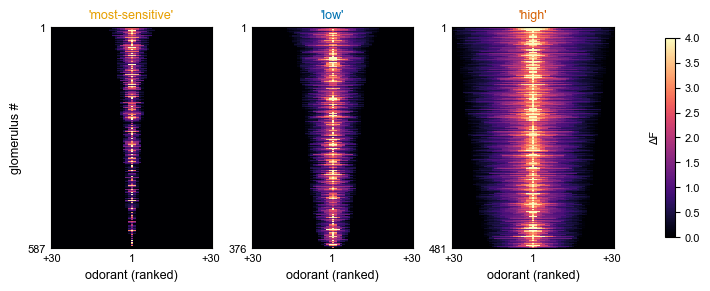

In [15]:
def rank_align(M, half_width=30):
    """Sort each row descending, centre on its peak, mirror out, NaN-pad."""
    M = np.asarray(M, float)
    out = np.full((M.shape[0], 2 * half_width + 1), np.nan)
    for i, row in enumerate(M):
        v = np.sort(row[np.isfinite(row)])[::-1]
        if v.size == 0:
            continue
        take = min(v.size, half_width + 1)
        out[i, half_width:half_width + take] = v[:take]
        out[i, half_width - take + 1:half_width + 1] = v[:take][::-1]
    return out

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.8), layout="constrained")
cmap = SEQ.copy(); cmap.set_bad(GAINSBORO)

for ax, (cond, n_glom, sparsity) in zip(axes, [("most-sensitive", 587, .93),
                                               ("low", 376, .82),
                                               ("high", 481, .58)]):
    M = rng.gamma(1.3, 1, (n_glom, 59))
    M[rng.random(M.shape) < sparsity] = 0
    R = rank_align(M)
    R = R[np.argsort(-(R > .01).sum(1))]        # broadest-tuned rows on top
    im = ax.imshow(R, aspect="auto", cmap=cmap, vmin=0, vmax=4,
                   interpolation="nearest")
    ax.set_title(f"'{cond}'", fontsize=FS_LABEL, color=CONDITION_COLORS[cond])
    ax.set_xticks([0, 30, 60]); ax.set_xticklabels(["+30", "1", "+30"])
    ax.set_xlabel("odorant (ranked)")
    ax.set_yticks([0, n_glom - 1]); ax.set_yticklabels(["1", str(n_glom)])
    ax.tick_params(length=0)
axes[0].set_ylabel("glomerulus #")
cb = fig.colorbar(im, ax=axes, fraction=.025, shrink=.9)   # ONE shared scale
cb.ax.yaxis.set_label_position("left")
cb.set_label("ΔF", fontsize=FS_TICK); cb.ax.tick_params(labelsize=FS_TICK)

save(fig, "05_2_rank_aligned"); plt.show()

All three panels share `vmin`/`vmax` and one colorbar, so the widening from
`'most-sensitive'` to `'high'` is a fact about the data rather than an artefact
of three independent scales. Panel titles are in the condition colours, which
lets the reader connect these to the cumulative curves above without a legend.

### §5.3 · Category strips on matrix axes

Chemical-family membership along the edge of a matrix: one coloured segment per
contiguous run, family name in the same colour. The categories have to be
**grouped** in the plotting order — and if they are not, the strip shows you
immediately, which is the reason to draw it rather than trust the ordering.

Note the palette: chemical families get their own colours, **not** the cluster
colours. They are a different categorical dimension, there are more of them than
there are clusters, and borrowing the cluster palette would both collide and
imply a correspondence that does not exist.

saved 05_3_class_strip.png / .pdf / .svg


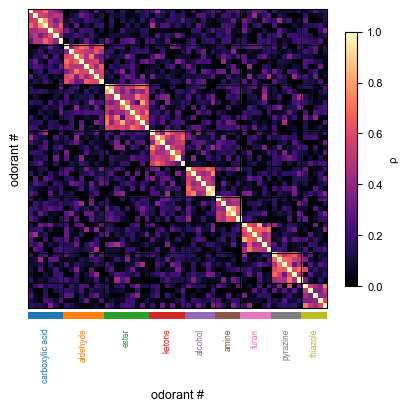

In [16]:
FAMILIES = ["carboxylic acid", "aldehyde", "ester", "ketone", "alcohol",
            "amine", "furan", "pyrazine", "thiazole"]
fam = np.repeat(np.arange(len(FAMILIES)), [7, 8, 9, 7, 6, 5, 6, 6, 5])[:59]
# Families are NOT clusters. Different categorical dimension, own palette,
# wide enough that no two families share a colour (7 cluster colours would
# collide across 9 families and imply a relationship that does not exist).
fam_colors = {f: plt.cm.tab10(i) for i, f in enumerate(FAMILIES)}

# within-family correlation is higher — the block structure the figure is about
C = np.eye(59)
for i in range(59):
    for j in range(i + 1, 59):
        base = .55 if fam[i] == fam[j] else .12
        C[i, j] = C[j, i] = np.clip(base + rng.normal(0, .12), 0, 1)

fig, ax = plt.subplots(figsize=(4.4, 4.0), layout="constrained")
im = ax.imshow(C, cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
for b in np.where(np.diff(fam) != 0)[0] + 1:
    ax.axvline(b - .5, color=BOUNDARY, lw=BOUNDARY_LW)
    ax.axhline(b - .5, color=BOUNDARY, lw=BOUNDARY_LW)
ax.set_xticks([]); ax.set_yticks([]); ax.tick_params(length=0)
ax.set_xlabel("odorant #", labelpad=58)      # room for the strip and labels
ax.set_ylabel("odorant #")

# the strip itself, in axis-fraction coords below the matrix
trans = ax.get_xaxis_transform()
runs, start = [], 0
for i in range(1, len(fam) + 1):
    if i == len(fam) or fam[i] != fam[start]:
        runs.append((start, i, FAMILIES[fam[start]])); start = i
for a, b, name in runs:
    ax.add_patch(plt.Rectangle((a - .5, -.035), b - a, .022, transform=trans,
                               clip_on=False, facecolor=fam_colors[name],
                               edgecolor="none"))
    ax.text((a + b - 1) / 2, -.065, name, transform=trans, rotation=90,
            ha="center", va="top", fontsize=6, color=fam_colors[name])

cb = fig.colorbar(im, ax=ax, fraction=.045, shrink=.85)
cb.set_label("ρ", fontsize=FS_TICK); cb.ax.tick_params(labelsize=FS_TICK)

save(fig, "05_3_class_strip"); plt.show()

---
## §6 · Illustrator-safe constructions

These are the five that cost real time on this project (STYLE_GUIDE §6). Each one below
produces output that looks the same in the PNG — the difference only appears when the
vector file is opened in Illustrator, which is exactly why they're easy to skip.

### §6.1 · Small matrices: vector cells, not a tiny image

A 7×7 `imshow` embeds as a 7×7 raster. Illustrator can drop it on import, and the panel
arrives with its cells simply missing. Drawing each cell as a rectangle looks identical
and always survives.

saved 05_1_vector_cells.png / .pdf / .svg


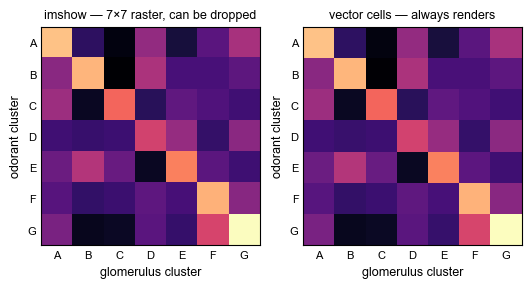

In [17]:
B = np.abs(rng.normal(.5, .3, (K, K)))
B[np.diag_indices(K)] += 1.1
B /= B.max()

fig, axes = plt.subplots(1, 2, figsize=(6.2, 3.0))

# --- fragile: a 7x7 raster ------------------------------------------------
axes[0].imshow(B, cmap=SEQ, vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title("imshow — 7×7 raster, can be dropped", fontsize=FS_LABEL)

# --- robust: 49 vector rectangles -----------------------------------------
ax = axes[1]
for r in range(K):
    for c in range(K):
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=SEQ(B[r, c]),
                                   edgecolor="none", zorder=0))  # under the frame
ax.set_xlim(-.5, K - .5); ax.set_ylim(K - .5, -.5); ax.set_aspect("equal")
ax.set_title("vector cells — always renders", fontsize=FS_LABEL)

for ax in axes:
    ax.set_xticks(range(K)); ax.set_xticklabels(CLUSTER_LABELS)
    ax.set_yticks(range(K)); ax.set_yticklabels(CLUSTER_LABELS)
    ax.tick_params(length=0)
    ax.set_xlabel("glomerulus cluster"); ax.set_ylabel("odorant cluster")

save(fig, "05_1_vector_cells"); plt.show()

### §6.2 · Missing data: opaque grey, not transparent

A raster with an alpha channel becomes a PDF soft mask, and Illustrator renders soft
masks wrong. Set `set_bad` / `set_under` to an **opaque** colour instead of leaving
cells transparent. Same picture, different PDF internals.

saved 05_2_opaque_missing.png / .pdf / .svg


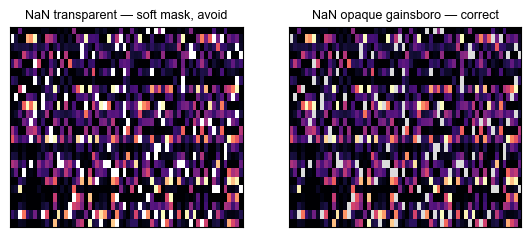

In [18]:
M = high[:60, :24].astype(float).copy()
M[rng.random(M.shape) < .08] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.6))

bad_transparent = SEQ.copy(); bad_transparent.set_bad(to_rgba("white", 0.0))
bad_opaque      = SEQ.copy(); bad_opaque.set_bad(GAINSBORO)

for ax, cm, t in [(axes[0], bad_transparent, "NaN transparent — soft mask, avoid"),
                  (axes[1], bad_opaque,      "NaN opaque gainsboro — correct")]:
    ax.imshow(np.ma.masked_invalid(M).T, aspect="auto", cmap=cm, vmin=0,
              vmax=np.nanpercentile(M, 98), interpolation="nearest")
    ax.set_title(t, fontsize=FS_LABEL)
    ax.set_xticks([]); ax.set_yticks([]); ax.tick_params(length=0)

save(fig, "05_2_opaque_missing"); plt.show()

### §6.3 · Shading a region: vector rectangle, not a raster overlay

`axvspan` is a selectable vector object with a real edge — easy to grab in Illustrator,
and it doesn't create a mask. A semi-transparent image drawn over the data does the
opposite of both.

saved 05_3_vector_shading.png / .pdf / .svg


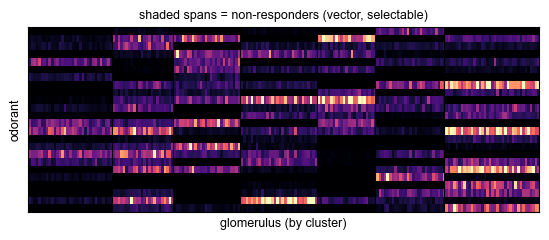

In [19]:
order = np.lexsort((~responder, glom_cluster))
seg = np.concatenate([[0], np.where(np.diff(glom_cluster[order]) != 0)[0] + 1,
                      [len(order)]])
# within each cluster, the trailing run of non-responders
spans = []
for a, b in zip(seg[:-1], seg[1:]):
    nr = ~responder[order][a:b]
    if nr.any():
        spans.append((a + int(np.argmax(nr)), b))

fig, ax = plt.subplots(figsize=(6.6, 2.4))
ax.imshow(high[order][:, :24].T, aspect="auto", cmap=SEQ, vmin=.05,
          vmax=np.percentile(high, 99), interpolation="nearest")
for s0, s1 in spans:                     # vector wash + clear left edge
    ax.axvspan(s0 - .5, s1 - .5, facecolor="white", alpha=.40,
               edgecolor="0.55", lw=.5, zorder=3)
for b in seg[1:-1]:
    ax.axvline(b - .5, color=BOUNDARY, lw=BOUNDARY_LW, zorder=4)
ax.set_title("shaded spans = non-responders (vector, selectable)", fontsize=FS_LABEL)
ax.set_xticks([]); ax.set_yticks([]); ax.tick_params(length=0)
ax.set_xlabel("glomerulus (by cluster)"); ax.set_ylabel("odorant")

save(fig, "05_3_vector_shading"); plt.show()

### §6.4 · Rescaling: re-render, never resize after import

Scaling a placed vector panel in Illustrator corrupts stroke weights and throws font
sizes out of step with the rest of the page. Render natively at the target scale
instead, with every dimension scaling together — and note that marker **area** scales
as the *square* of the linear factor.

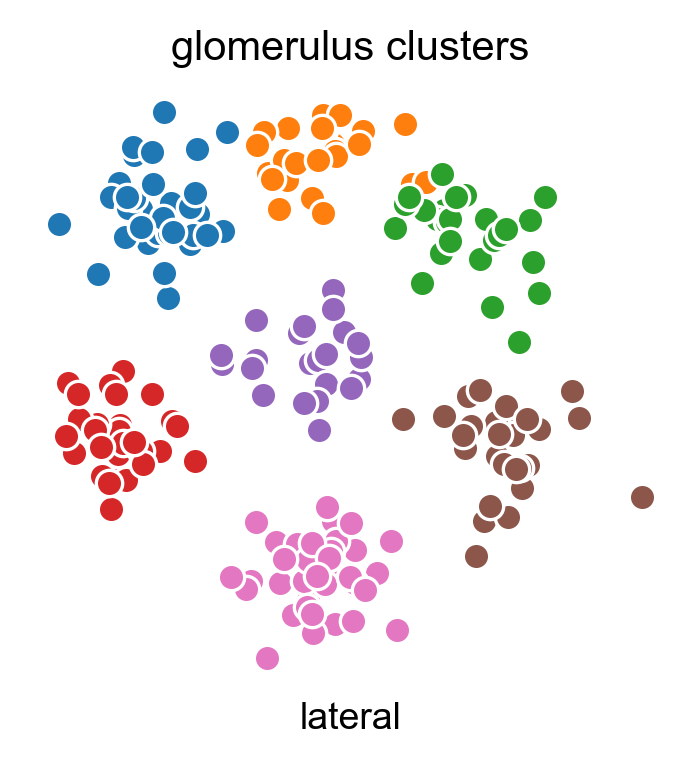

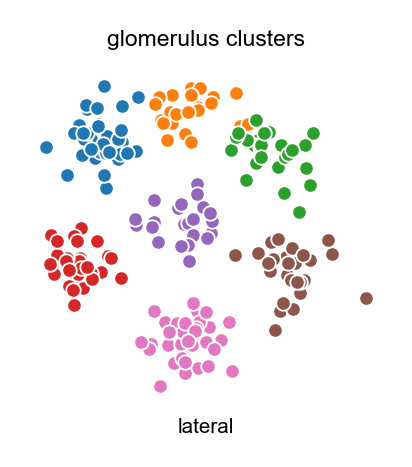

two independently rendered sizes — neither needs resizing in Illustrator


In [20]:
def render_scaled(scale, stem):
    """Everything scales together: canvas, fonts, line widths, marker areas."""
    z = scale
    fig, ax = plt.subplots(figsize=(3.4 * z, 2.6 * z), dpi=300)
    for k in range(K):
        m = glom_cluster == k
        ax.scatter(xy[m, 0], xy[m, 1], s=40 * z**2,          # AREA -> z squared
                   color=CLUSTER_COLORS[k], edgecolors="white",
                   linewidths=.8 * z, zorder=2)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("glomerulus clusters", fontsize=FS_TITLE * z)
    ax.set_xlabel("lateral", fontsize=FS_LABEL * z)
    despine(ax, keep=())
    for s in ax.spines.values():
        s.set_linewidth(.8 * z)
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight", facecolor="none",
                transparent=True)
    return fig

fig_full = render_scaled(1.0, "05_4_scale_full")
fig_small = render_scaled(0.55, "05_4_scale_small")   # ~55%: render, do NOT resize
plt.show()
print("two independently rendered sizes — neither needs resizing in Illustrator")

---
## §7 · Export, and checking that it worked

The `save()` helper in §0 writes the trio. The check below is the useful part: it opens
the SVG and confirms the labels are still **live text**, not outlined paths. Run it once
on your own pipeline's output — it takes a second and catches the single most common
handover failure.

In [21]:
import re

fig, ax = plt.subplots(figsize=(3.2, 2.4))
ax.scatter(high[:, 2], pred[:, 2], s=6.5, linewidths=0, alpha=.55, color=C_PRIMARY)
ax.set_xlabel("observed ΔF/F"); ax.set_ylabel("predicted ΔF/F")
despine(ax)
save(fig, "06_export_check")
plt.close(fig)

svg = (OUT / "06_export_check.svg").read_text()
texts = re.findall(r"<text[^>]*>(.*?)</text>", svg, flags=re.S)
labels = [t for t in texts if "observed" in t or "predicted" in t]

fonts = set(re.findall(r"font-family:\s*([^;\"]+)", svg)) or {"none declared"}

print(f"<text> elements in the SVG : {len(texts)}")
print(f"axis labels found as text  : {labels}")
print(f"font referenced            : {sorted(fonts)}")
print()
print("PASS — text is live and editable" if labels else
      "FAIL — labels were outlined or rasterised")

saved 06_export_check.png / .pdf / .svg
<text> elements in the SVG : 13
axis labels found as text  : ['observed Î”F/F', 'predicted Î”F/F']
font referenced            : ["'Arial', 'Helvetica', 'DejaVu Sans', sans-serif"]

PASS — text is live and editable


A raster check too: a PDF that secretly contains a bitmap of the whole panel is the
other common failure. A vector PDF from a scatter of this size is a few tens of kB; a
rasterised one is much larger and scales with dpi rather than with the number of points.

In [22]:
for stem in ("06_export_check", "04_1_parity", "05_1_vector_cells"):
    kb = (OUT / f"{stem}.pdf").stat().st_size / 1024
    print(f"{stem:22s} {kb:7.1f} kB pdf")
print("\n(Sizes in this range are vector. A panel that jumps to several MB "
      "has been rasterised somewhere in the chain.)")

06_export_check           22.9 kB pdf
04_1_parity              152.4 kB pdf
05_1_vector_cells         27.3 kB pdf

(Sizes in this range are vector. A panel that jumps to several MB has been rasterised somewhere in the chain.)


---
## §8 · Multi-panel assembly at final size

The figure below is 7.0 in wide — full manuscript width — so every font size and line
width in it is the size a reader sees. In practice panels are assembled in Illustrator,
but building the layout in code first is worth it: it tells you immediately whether the
type survives at final size, which a large working render never does.

saved 07_assembled_figure.png / .pdf / .svg


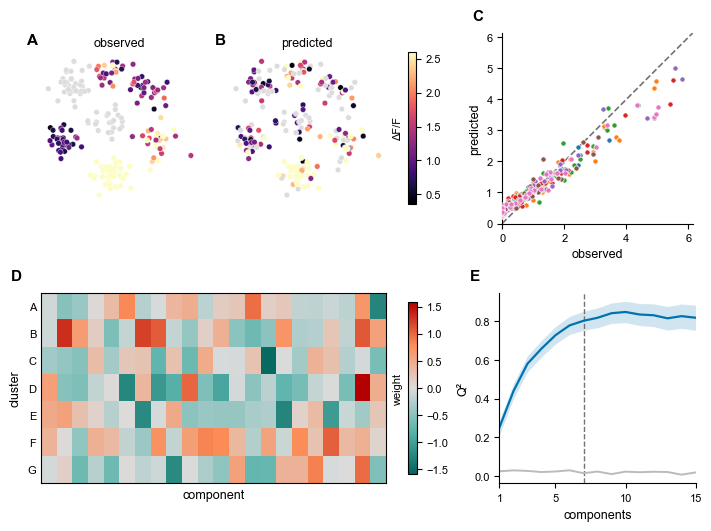

In [23]:
# layout="constrained" lets matplotlib reserve space for colorbars and labels
# instead of hand-tuning gaps — the single biggest saver on multi-panel figures.
fig = plt.figure(figsize=(7.0, 5.2), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.25], height_ratios=[1, 1])

cmap = SEQ.copy(); cmap.set_under(GAINSBORO)

# A / B — the topography pair, one shared scale and one shared colorbar
axA = fig.add_subplot(gs[0, 0])
sc = axA.scatter(xy[:, 0], xy[:, 1], c=high[:, odor], s=16, cmap=cmap,
                 vmin=MAP_VMIN, vmax=MAP_VMAX, linewidths=.25, edgecolors="white")
axA.set_title("observed", fontsize=FS_LABEL)

axB = fig.add_subplot(gs[0, 1])
axB.scatter(xy[:, 0], xy[:, 1], c=pred[:, odor], s=16, cmap=cmap,
            vmin=MAP_VMIN, vmax=MAP_VMAX, linewidths=.25, edgecolors="white")
axB.set_title("predicted", fontsize=FS_LABEL)

for ax in (axA, axB):
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); despine(ax, keep=())
panel_label(axA, "A", x=-.02); panel_label(axB, "B", x=-.02)

cb = fig.colorbar(sc, ax=[axA, axB], fraction=.05, pad=.02, shrink=.80)
cb.ax.yaxis.set_label_position("left")
cb.set_label("\N{GREEK CAPITAL LETTER DELTA}F/F", fontsize=FS_TICK, labelpad=4)
cb.ax.tick_params(labelsize=FS_TICK)

# C — cluster x odorant parity
axC = fig.add_subplot(gs[0, 2])
for k in range(K):
    axC.scatter(obs_c[:, k], prd_c[:, k], s=14, color=CLUSTER_COLORS[k],
                edgecolors="white", linewidths=.5, zorder=3)
lim = max(obs_c.max(), prd_c.max()) * 1.06
axC.plot([0, lim], [0, lim], ls="--", lw=1.2, color=IDENTITY, zorder=1)
axC.set(xlim=(0, lim), ylim=(0, lim), xlabel="observed", ylabel="predicted")
axC.set_aspect("equal"); despine(axC); panel_label(axC, "C")

# D — weight matrix, symmetric limits, frame kept (it is an image)
axD = fig.add_subplot(gs[1, :2])
Wbig = rng.normal(0, .6, (K, 22))
vmax = np.abs(Wbig).max()
im = axD.imshow(Wbig, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto",
                interpolation="nearest")
axD.set_yticks(range(K)); axD.set_yticklabels(CLUSTER_LABELS)
axD.set_xticks([]); axD.tick_params(length=0)
axD.set_xlabel("component"); axD.set_ylabel("cluster")
cbD = fig.colorbar(im, ax=axD, fraction=.035, pad=.02, shrink=.9)
cbD.ax.yaxis.set_label_position("left")
cbD.set_label("weight", fontsize=FS_TICK, labelpad=4)
cbD.ax.tick_params(labelsize=FS_TICK)
panel_label(axD, "D", x=-.055)

# E — rank sweep
axE = fig.add_subplot(gs[1, 2])
axE.fill_between(ranks, q2 - spread, q2 + spread, color=C_PRIMARY, alpha=.18, lw=0)
axE.plot(ranks, q2, lw=1.6, color=C_PRIMARY)
axE.plot(ranks, null, lw=1.4, color=C_SHUFFLED)
axE.axvline(CHOSEN, color=IDENTITY, ls="--", lw=1.0, zorder=1)
axE.set(xlabel="components", ylabel="Q\N{SUPERSCRIPT TWO}", xlim=(1, 15))
axE.set_xticks([1, 5, 10, 15])          # integer ranks, not 2.5 / 7.5
despine(axE); panel_label(axE, "E")

save(fig, "07_assembled_figure"); plt.show()

---
## §9 · Porting the conventions

The values are the portable part; the API isn't. Rough equivalents:

| Convention | matplotlib | MATLAB | R / ggplot2 |
|---|---|---|---|
| Editable-text vector | `svg.fonttype="none"`, `pdf.fonttype=42` | `exportgraphics(...,'ContentType','vector')` | `svglite::svglite()`, `cairo_pdf` |
| Transparent background | `transparent=True` | `'BackgroundColor','none'` | `bg = "transparent"` |
| Tight crop | `bbox_inches="tight"` | `'ContentType','vector'` + tight axes | `ggsave` respects panel extents |
| Sequential map | `plt.cm.magma` | `colormap(readmatrix('seq_magma_256.csv'))` | `scale_fill_viridis_c(option="magma")` |
| Diverging map | `LinearSegmentedColormap.from_list(...)` | `readmatrix('div_teal_gainsboro_orrd_256.csv')` | `scale_fill_gradientn(colours=…)` |
| Zero-centred diverging | `vmin=-vmax` | `clim([-v v])` | `limits = c(-v, v)` |
| Below-floor grey | `cmap.set_under(GAINSBORO)` | set the first colormap row | `na.value = "#dcdcdc"` |
| Spines off | `spines[...].set_visible(False)` | `box off`, `ax.YAxis.Visible` | `theme_classic()` |
| No smoothing | `interpolation="nearest"` | `imagesc` (default) | `geom_raster()` |

The 256-row CSVs in `palette/` exist precisely for the middle rows of that table: any
tool that can read a CSV of RGB values can reproduce these colormaps exactly, without
anyone re-typing five hex codes and getting one wrong.

**One last time, because it's the thing that actually breaks:** send the numbers behind
the panel along with the panel. A figure can be rebuilt from data; it cannot be rebuilt
from a PDF.